In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("leads_clean.csv")

# FIX: Force money column to be numbers, not text
df['estimated_value_zar'] = pd.to_numeric(df['estimated_value_zar'], errors='coerce')

print("Clean rows:", len(df))
print(df.head())
print("\nColumns:", list(df.columns))
print("\nValue column type:", df['estimated_value_zar'].dtype)

Clean rows: 63
  lead_id lead_created_at        source          status  estimated_value_zar
0  LD-001      2026-11-11      Whatsapp  Not Interested               4000.0
1  LD-002      2026-10-19      Referral             New               1500.0
2  LD-003      2026-10-17  Social Media      Interested               4000.0
3  LD-004      2026-10-24      Whatsapp       Contacted               2500.0
4  LD-005      2026-10-16      Whatsapp             New              20000.0

Columns: ['lead_id', 'lead_created_at', 'source', 'status', 'estimated_value_zar']

Value column type: float64


In [5]:
# --- Find the value column automatically ---
value_col = [c for c in df.columns if 'estimated' in c][0]
print("Using value column:", value_col)

# --- 1. Leads by Source ---
print("\n--- 1. Leads by Source ---")
print(df['source'].value_counts())

# --- 2. Converted leads by Source ---
print("\n--- 2. Converted leads by Source ---")
converted = df[df['status'] == 'Converted']
print(converted['source'].value_counts())

# --- 3. Conversion Rate + Value by Source ---
print("\n--- 3. Conversion Rate + Value by Source ---")
summary = df.groupby('source').agg(
    total_leads=('lead_id', 'count'),
    converted_leads=('status', lambda x: (x == 'Converted').sum()),
    total_value=(value_col, 'sum')
)
summary['conversion_rate_%'] = (summary['converted_leads'] / summary['total_leads'] * 100).round(1)
print(summary.sort_values('conversion_rate_%', ascending=False))

# --- 4. Total Estimated Value by Status (ZAR) ---
print("\n--- 4. Total Estimated Value by Status (ZAR) ---")
print(df.groupby('status')[value_col].sum().sort_values(ascending=False))

# --- 5. Average Deal Size by Source ---
print("\n--- 5. Average Deal Size by Source ---")
print(df.groupby('source')[value_col].mean().round(0).sort_values(ascending=False))


Using value column: estimated_value_zar

--- 1. Leads by Source ---
source
Referral        16
Social Media    14
Website         13
Whatsapp        12
Google Ads       7
Name: count, dtype: int64

--- 2. Converted leads by Source ---
source
Google Ads      3
Social Media    3
Website         1
Referral        1
Name: count, dtype: int64

--- 3. Conversion Rate + Value by Source ---
              total_leads  converted_leads  total_value  conversion_rate_%
source                                                                    
Google Ads              7                3      59000.0               42.9
Social Media           14                3      74500.0               21.4
Website                13                1      71000.0                7.7
Referral               16                1     122000.0                6.2
Whatsapp               12                0      71500.0                0.0

--- 4. Total Estimated Value by Status (ZAR) ---
status
Interested        111500.0
New   

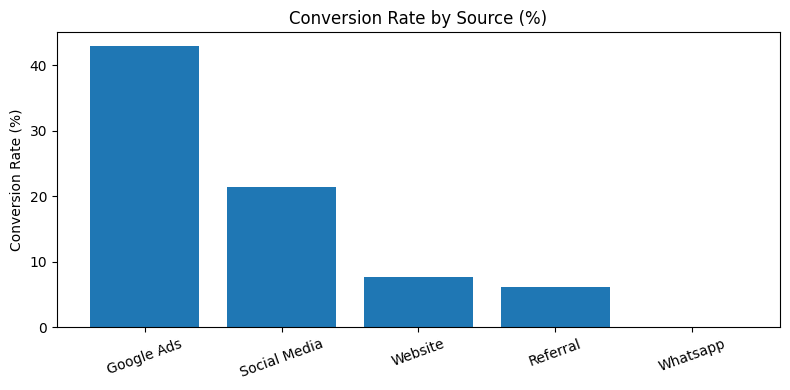

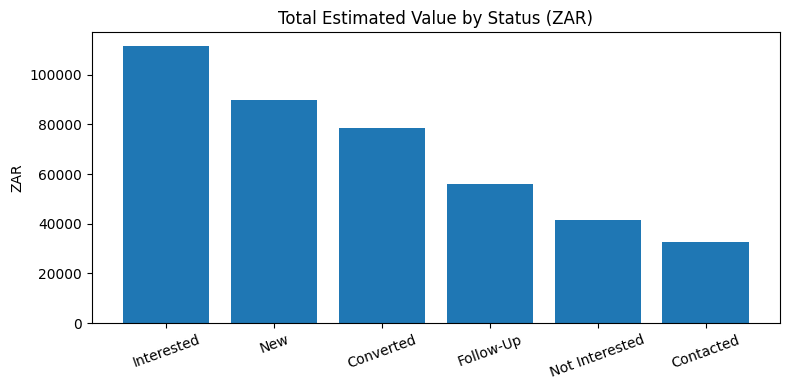

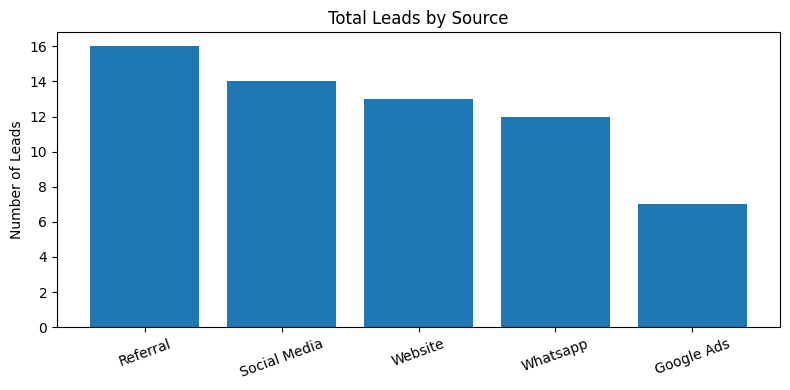

In [6]:
# Chart 1: Conversion Rate by Source
summary_sorted = summary.sort_values('conversion_rate_%', ascending=False)
plt.figure(figsize=(8, 4))
plt.bar(summary_sorted.index, summary_sorted['conversion_rate_%'])
plt.title('Conversion Rate by Source (%)')
plt.ylabel('Conversion Rate (%)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Chart 2: Total Value by Status
status_value = df.groupby('status')[value_col].sum().sort_values(ascending=False)
plt.figure(figsize=(8, 4))
plt.bar(status_value.index, status_value.values)
plt.title('Total Estimated Value by Status (ZAR)')
plt.ylabel('ZAR')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Chart 3: Leads by Source
plt.figure(figsize=(8, 4))
plt.bar(df['source'].value_counts().index, df['source'].value_counts().values)
plt.title('Total Leads by Source')
plt.ylabel('Number of Leads')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
